# CNN for patches of 15x15 pixels with the position of the center

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from common.config import (
    MAT_PATH,
    FIGS_DIR,
    TARGET_CLASS_NAMES,
    VALIDATION_FRACTION,
    TEST_FRACTION,
    RANDOM_STATE,
)
from common.utils import NYUDepthV2, make_data_splits, build_patches_dataset, binary_target_mask, extract_patch,evaluate

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, jaccard_score, roc_auc_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.utils.class_weight import compute_class_weight

import keras
from keras.models import Sequential, Model
from keras.layers import Dense, Activation, Conv2D, MaxPooling2D, Flatten, Dropout, Input, Concatenate

N_PIXELS = 100
PATCH_SIZE = 15
INCLUDE_POSITION = True

I0000 00:00:1795533179.699848   82879 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795533179.702954   82879 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795533179.844420   82879 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795533185.132432   82879 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

In [2]:
nyu = NYUDepthV2(MAT_PATH)
target_ids = [nyu.class_names.index(target) + 1 for target in TARGET_CLASS_NAMES]

In [3]:
# Create train/validation/test image indices
train_indices, val_indices, test_indices = make_data_splits(
    nyu_dataset=nyu,
    validation_fraction=VALIDATION_FRACTION,
    test_fraction=TEST_FRACTION,
    random_state=RANDOM_STATE,
)
print(f"Train images: {len(train_indices)}")
print(f"Validation images: {len(val_indices)}")
print(f"Test images: {len(test_indices)}")

Train images: 1028
Validation images: 206
Test images: 215


In [4]:
X_train, y_train, pos_train = build_patches_dataset(nyu, train_indices, target_ids,PATCH_SIZE, N_PIXELS, RANDOM_STATE,INCLUDE_POSITION)
X_test, y_test, pos_test = build_patches_dataset(nyu, test_indices, target_ids,PATCH_SIZE, N_PIXELS, RANDOM_STATE,INCLUDE_POSITION)
X_val, y_val, pos_val = build_patches_dataset(nyu, val_indices, target_ids, PATCH_SIZE, N_PIXELS, RANDOM_STATE,INCLUDE_POSITION)

In [5]:
# Part 1: the CNN that looks at the patch (plain Sequential)
cnn = Sequential([
    Input(shape=X_train[0].shape),          # (15, 15, 3)
    Conv2D(32, (3, 3), padding='same', activation='relu'),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Dropout(0.25),
    Conv2D(64, (3, 3), padding='same', activation='relu'),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Dropout(0.25),
    Flatten(),                              # -> 256 numbers
])

# Part 2: the classifier on top (plain Sequential)
head = Sequential([
    Input(shape=(256 + 2,)),                # patch features + (x, y)
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid'),
])

# Join them: the only non-Sequential part
patch_in = Input(shape=X_train[0].shape)
pos_in   = Input(shape=(2,))
out = head(Concatenate()([cnn(patch_in), pos_in]))
model = Model(inputs=[patch_in, pos_in], outputs=out)

E0000 00:00:1795533247.231335   82879 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [6]:
model.compile(optimizer='adam',
  loss='binary_crossentropy',
  metrics=['accuracy', keras.metrics.AUC(name='auc')])

In [7]:
weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight = {0: weights[0], 1: weights[1]}

early_stop = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max",
                                           patience=5, restore_best_weights=True)

history = model.fit([X_train, pos_train], y_train,
                    epochs=30, batch_size=256,
                    validation_data=([X_val, pos_val], y_val),
                    class_weight=class_weight,
                    callbacks=[early_stop])

Epoch 1/30
402/402 ━━━━━━━━━━━━━━━━━━━━ 30s 66ms/step - accuracy: 0.7569 - auc: 0.8752 - loss: 0.4482 - val_accuracy: 0.7441 - val_auc: 0.8955 - val_loss: 0.5118
Epoch 2/30
402/402 ━━━━━━━━━━━━━━━━━━━━ 29s 71ms/step - accuracy: 0.7952 - auc: 0.9015 - loss: 0.3830 - val_accuracy: 0.7695 - val_auc: 0.9016 - val_loss: 0.4533
Epoch 3/30
402/402 ━━━━━━━━━━━━━━━━━━━━ 29s 71ms/step - accuracy: 0.7981 - auc: 0.9037 - loss: 0.3777 - val_accuracy: 0.7615 - val_auc: 0.9006 - val_loss: 0.4892
Epoch 4/30
402/402 ━━━━━━━━━━━━━━━━━━━━ 28s 69ms/step - accuracy: 0.8012 - auc: 0.9055 - loss: 0.3732 - val_accuracy: 0.7778 - val_auc: 0.9037 - val_loss: 0.4295
Epoch 5/30
402/402 ━━━━━━━━━━━━━━━━━━━━ 29s 71ms/step - accuracy: 0.8028 - auc: 0.9087 - loss: 0.3676 - val_accuracy: 0.7781 - val_auc: 0.9029 - val_loss: 0.4378
Epoch 6/30
402/402 ━━━━━━━━━━━━━━━━━━━━ 30s 74ms/step - accuracy: 0.8038 - auc: 0.9089 - loss: 0.3673 - val_accuracy: 0.7804 - val_auc: 0.9034 - val_loss: 0.4408
Epoch 7/30
402/402 ━━━━━━━━━

21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step
AUC:      0.911
AP:       0.566
Accuracy: 0.812  (baseline 'always not floor': 0.885)
IoU:      0.343
              precision    recall  f1-score   support

   not floor       0.98      0.81      0.88     19035
       floor       0.36      0.86      0.51      2465

    accuracy                           0.81     21500
   macro avg       0.67      0.83      0.70     21500
weighted avg       0.91      0.81      0.84     21500



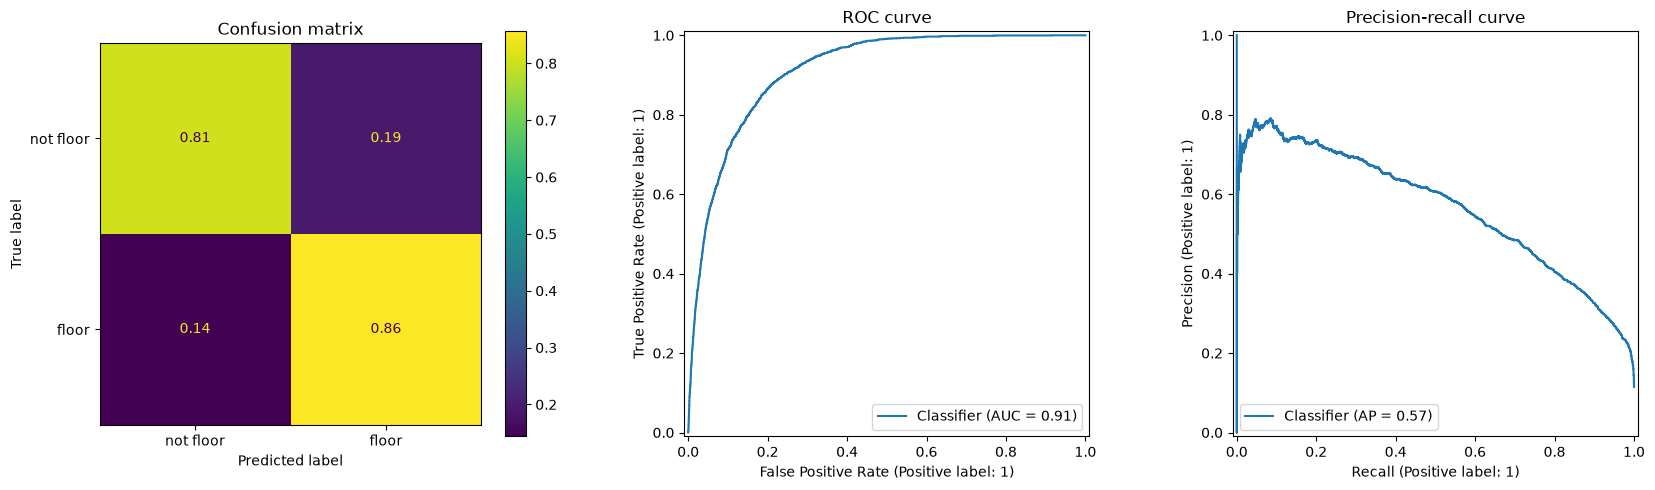

In [8]:
y_proba = model.predict([X_test, pos_test], batch_size=1024).ravel()
evaluate(y_test, y_proba)

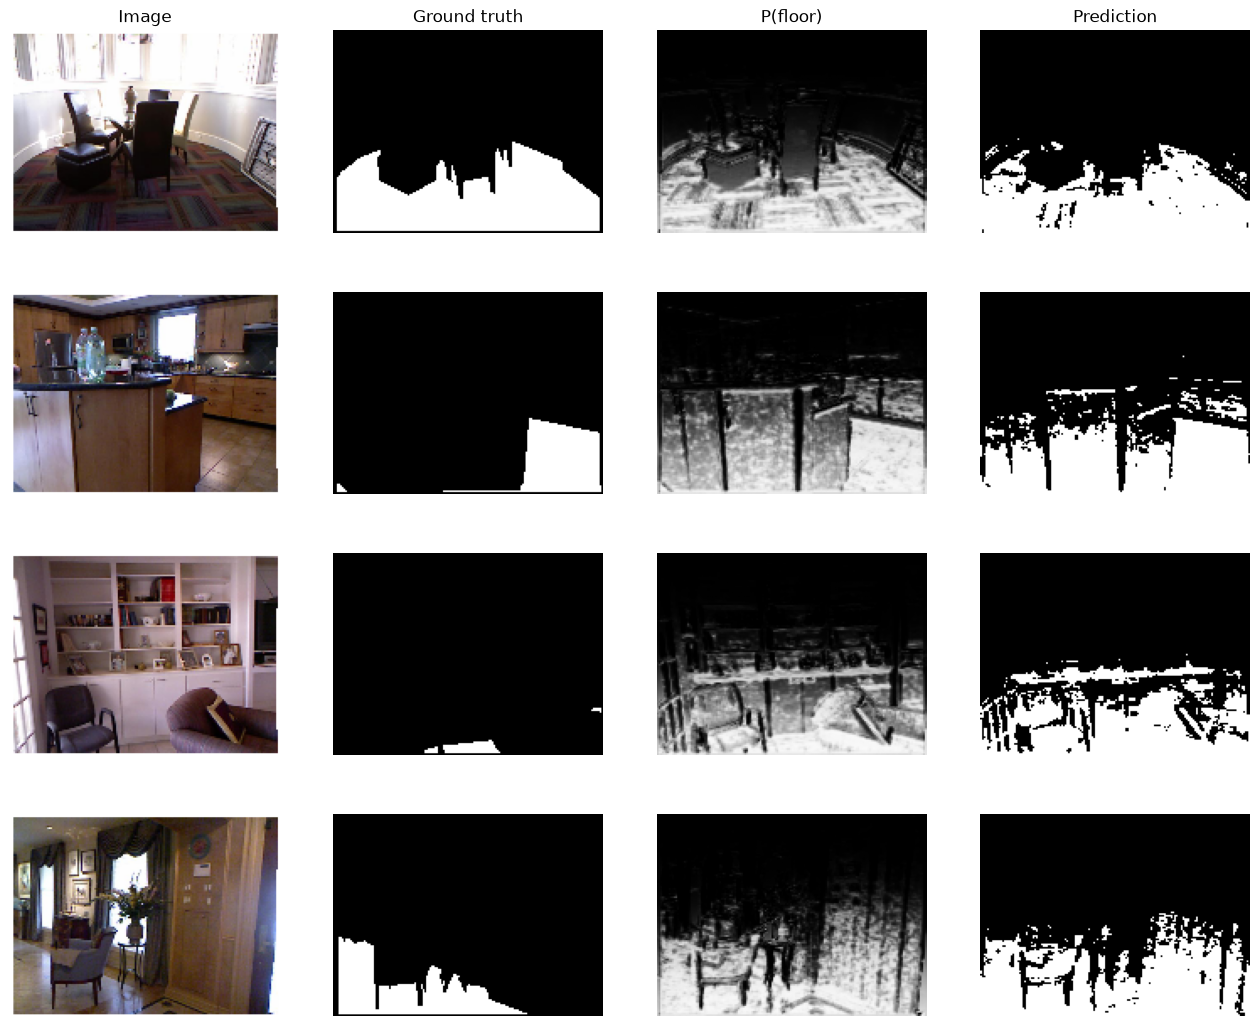

In [9]:
STRIDE = 4   # predict one pixel every 4 (faster)
p = PATCH_SIZE // 2

fig, axes = plt.subplots(4, 4, figsize=(16, 13))

for row, idx in enumerate(test_indices[:4]):
    image, labels = nyu.get_pair(idx)
    gt = binary_target_mask(labels, target_ids)

    # Build one patch for each pixel on the grid
    padded = np.pad(image, ((p, p), (p, p), (0, 0)), mode="edge")
    rows = range(0, image.shape[0], STRIDE)
    cols = range(0, image.shape[1], STRIDE)
    h, w = image.shape[:2]
    X = np.array([extract_patch(padded, r + p, c + p, PATCH_SIZE) for r in rows for c in cols])
    X = X.astype(np.float32) / 255.0
    pos = np.array([(r / (h - 1), c / (w - 1)) for r in rows for c in cols], dtype=np.float32)

    # Predict and put back into a (small) image
    proba = model.predict([X, pos], batch_size=2048, verbose=0).reshape(len(rows), len(cols))
    pred = proba > 0.5

    axes[row, 0].imshow(image[::STRIDE, ::STRIDE])
    axes[row, 1].imshow(gt[::STRIDE, ::STRIDE], cmap="gray")
    axes[row, 2].imshow(proba, cmap="gray", vmin=0, vmax=1)
    axes[row, 3].imshow(pred, cmap="gray")

axes[0, 0].set_title("Image")
axes[0, 1].set_title("Ground truth")
axes[0, 2].set_title("P(floor)")
axes[0, 3].set_title("Prediction")

for ax in axes.ravel():
    ax.axis("off")

plt.show()